In [91]:
import numpy as np

import pandas as pd
from pandas.api.types import CategoricalDtype

%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import linear_model as lm
from sklearn.model_selection import train_test_split

import os

from feature_func import *

# Plot settings

plt.rcParams['figure.figsize'] = (12, 9)
plt.rcParams['font.size'] = 12

In [92]:
training_val_data = pd.read_csv("housing_train_val.csv", index_col='Unnamed: 0')
test_data = pd.read_csv("housing_test.csv", index_col='Unnamed: 0')
from feature_func import remove_outliers


In [93]:
training_val_data = remove_outliers(training_val_data, 'Sale Price', lower=499)
training_val_data["Log Sale Price"] = np.log(training_val_data["Sale Price"])

In [94]:
len(training_val_data)

168931

In [95]:
Xonly = training_val_data.drop(columns=['Log Sale Price', 'Sale Price'])

In [96]:
x_train, x_val, y_train, y_val = train_test_split(
    Xonly,
    training_val_data['Log Sale Price'],
    test_size=0.2,
    random_state=42
)

<Axes: >

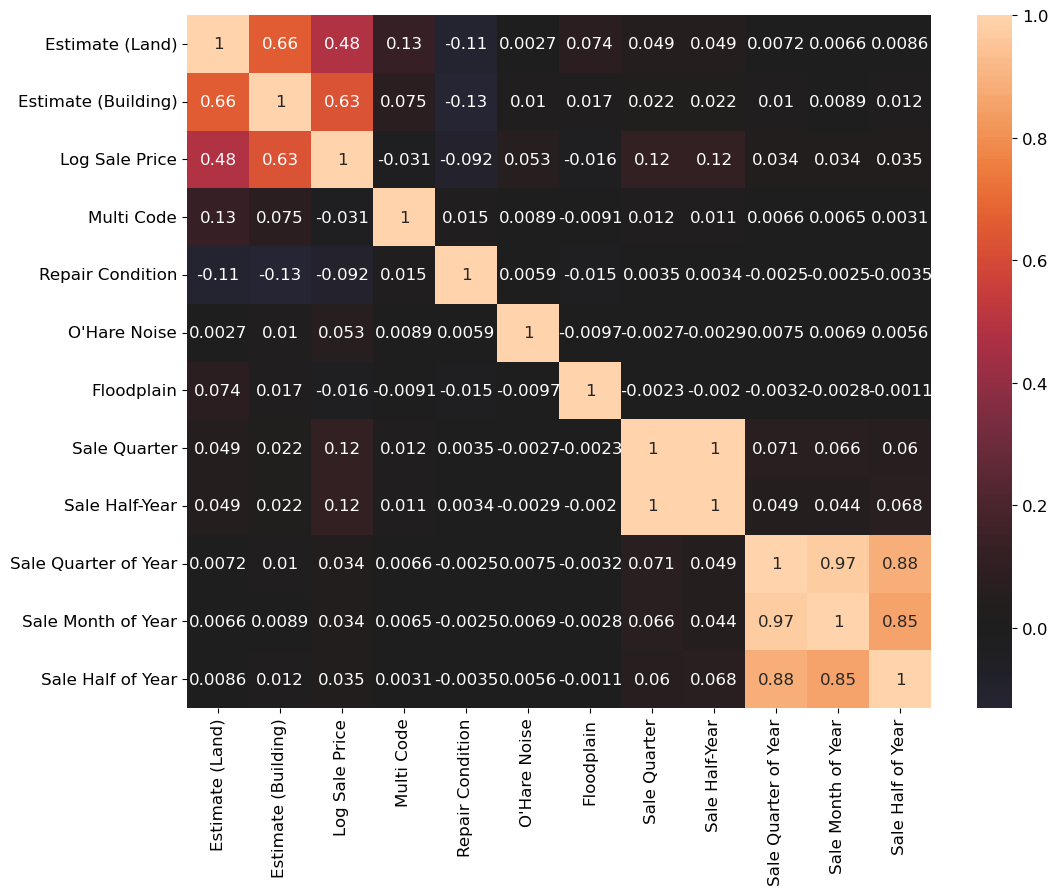

In [97]:
q3b_features = ['Estimate (Land)', 'Estimate (Building)', 'Log Sale Price', 'Multi Code', 'Repair Condition', "O'Hare Noise", 'Floodplain', 'Sale Quarter', 'Sale Half-Year', 'Sale Quarter of Year', 'Sale Month of Year', 'Sale Half of Year'] 
sns.heatmap(data=training_val_data[q3b_features].corr(numeric_only=True), annot=True, center=0)

In [98]:
def ohe(data, labels):
    """
    One-hot encode the specified columns.
    """
    assert isinstance(labels, list), "labels must be a list of columns"

    encoder = OneHotEncoder()
    encoder.fit(data[labels])

    dummies = pd.DataFrame(
        encoder.transform(data[labels]).todense(),
        columns=encoder.get_feature_names_out(),
        index=data.index
    )

    return data.join(dummies), encoder.get_feature_names_out()

def bin_col(data, colname, granularity):
    """
    Put a numerical column into categorical bins.
    """
    data = data.copy()

    min_value = data[colname].min()

    data[colname + " Bin"] = (
        (data[colname] - min_value) // granularity
    ).astype(str)

    return data

#since I cannot use "Sale Price" and "Log Sale Price" in my model, I will base this function on the "Estimate (Building)" and "Estimate (Land)" variables
#the sum of these two variables will take the place of the original "Log Sale Price"
def find_expensive_neighborhoods(data, n, metric=np.median):
    data['Sum of Estimates'] = data['Estimate (Land)'] + data['Estimate (Building)']
    neighborhoods = list(
        data
        .groupby('Neighborhood Code')['Sum of Estimates']
        .aggregate(metric)
        .sort_values(ascending=False)
        .head(n)
        .index.values
    )

    return [int(code) for code in neighborhoods]

In [ ]:
expNeighborhoods = find_expensive_neighborhoods(training_val_data, 3)

# Please include all of your feature engineering processes inside this function.
# Do not modify the parameters of this function.
def final_model_pipeline(df): 
    # make a copy to avoid modifying the original dataframe
    data = df.copy()

    # We can see the sale price so this must be a training set. Test sets will not have
    # the Sale Price column available. Let's avoid fitting house prices that are either
    # very low or very high. Do not remove this code, as keeping all the one dollar houses
    # and super expensive houses will affect your model negatively.
    if "Sale Price" in data.columns:
        data = remove_outliers(data, 
                               variable='Sale Price',
                               upper=1_000_000)

        # drop the sale price if present to avoid accidentally using these in the model
        data = data.drop(["Sale Price", "Log Sale Price"], axis='columns')

    #Rooms
    data = add_total_bedrooms(data)
    data = add_total_bathrooms(data)

    #Expensive Neighborhoods
    data = add_in_expensive_neighborhood(data, expNeighborhoods)

    #Logs
    data = log_transform(data, 'Building Square Feet')
    data = log_transform(data, 'Land Square Feet')

    #OHE 
    categorical_cols = [
    "Wall Material",
    "Basement Finish",
    "Central Heating",
    "Roof Material",
    "Construction Quality",
    "Site Desirability",
    "Garage 1 Size",
    "Garage 1 Material",
    "Property Class",
    "Repair Condition",
    "Multi Code"]

    data, ohe_cols = ohe(data, categorical_cols)
    
    finalData = data[['Log Building Square Feet', 'Estimate (Land)', 'Estimate (Building)','Log Land Square Feet', 'Bathrooms', 'Bedrooms', 'Age', 'Most Recent Sale', 'Lot Size', 'Sale Quarter', 'in_expensive_neighborhood'] 
              + list(ohe_cols)]
    return finalData

In [ ]:
def make_feature_engine_adapter(pipeline):
    """
    Adapt final_model_pipeline(df) -> X to the A2 interface:

        feature_engine_final(train_data) -> (X, y)
        feature_engine_final(test_data, is_test_set=True) -> X
    """
    training_columns = None

    def feature_engine_final(data, is_test_set=False):
        nonlocal training_columns

        working_data = data.copy()

        if is_test_set:

            pipeline_input = working_data.drop(
                columns=["Sale Price", "Log Sale Price"],
                errors="ignore"
            )

            X = pipeline(pipeline_input)


            if len(X) != len(working_data):
                raise ValueError(
                    "The pipeline removed rows from validation/test data."
                )

            if not X.index.equals(working_data.index):
                raise ValueError(
                    "The pipeline changed or reordered validation/test indices."
                )

            if training_columns is None:
                raise RuntimeError(
                    "Call feature_engine_final on training data before "
                    "processing validation/test data."
                )


            X = X.reindex(columns=training_columns, fill_value=0)

            return X


        if "Sale Price" not in working_data.columns:
            raise ValueError(
                "Training data must contain a Sale Price column."
            )


        working_data = working_data.loc[
            working_data["Sale Price"] > 499
        ].copy()


        working_data["Log Sale Price"] = np.log(
            working_data["Sale Price"]
        )


        y = working_data["Log Sale Price"].copy()
        X = pipeline(working_data)


        y = y.loc[X.index]

        if not X.index.equals(y.index):
            raise ValueError("X and y are not aligned.")

        training_columns = X.columns.copy()

        return X, y

    return feature_engine_final


feature_engine_final = make_feature_engine_adapter(
    final_model_pipeline
)

In [ ]:
check_rmse_threshold = run_linear_regression_test_optim(
    lm.LinearRegression(fit_intercept=True),
    feature_engine_final,
    "housing_train.csv",
    None,
    False
)

print(
    "Current training log RMSE:",
    check_rmse_threshold.loss
)

In [ ]:
def rmse(predicted, actual):
    return np.sqrt(np.mean((actual - predicted)**2))

In [ ]:
from sklearn.model_selection import KFold

def compute_CV_error(X_train, Y_train, folds=10):
    model = lm.LinearRegression(fit_intercept=True) # Use model that Question 5 requires.
    kf = KFold(n_splits=folds)
    validation_errors = []
    
    for train_idx, valid_idx in kf.split(X_train):



        # 1. For each fold, it computes the indices of the training and validating sets and assigns the corresponding rows of X_train's features and Y_train's labels to its corresponding variable
        split_X_train, split_X_valid = X_train.iloc[train_idx], X_train.iloc[valid_idx]
        split_Y_train, split_Y_valid = Y_train.iloc[train_idx], Y_train.iloc[valid_idx]
      
      
        # 2. For each fold, it fits the Linear Regression model using the training set (including both X_train's features and Y-train's labels)
        model.fit(split_X_train, split_Y_train)

        # 3. For each fold, calculate the Root Mean Sqare Error using the predicted labels and the actual labels
        error = rmse(model.predict(split_X_valid), split_Y_valid)


        validation_errors.append(error)

    return validation_errors

In [ ]:
compute_CV_error(final_model_pipeline(training_val_data), training_val_data['Log Sale Price'], 4)